# Part 3: Downstream Representation Analysis
**Task:** authorship attribution : is a passage by **Alcott** (*Little Men*) or **Austen** (*Pride and Prejudice*)?
Neither book was seen by any language model (they were trained on *Little Women* only), so there is no leakage.

**Comparison question:** *Does better next-token prediction on Alcott give representations that better recognise Alcott's writing?*

| Comparison | Representations |
|---|---|
| **Main (required)** | LSTM vs Transformer from Part I, each with **mean pooling** and **final-state pooling** |
| **Extension** | All 5 trained LMs (RNN, LSTM, Transformer + the two Part 2 LSTMs) with mean pooling → does LM perplexity ranking match classification ranking? |
| **Reference baselines** | (a) `<unk>`-rate only, (b) bag-of-words TF-IDF ,shows how much a simple lexical model gets |

All language models are **frozen**; only a logistic-regression classifier is trained. Same classifier, same tuning procedure, same splits for every representation.




In [3]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys
BASE = '/content/drive/MyDrive/DSA4213_A1'
DATA, OUT = f'{BASE}/data', f'{BASE}/outputs'
sys.path.append(BASE)
for f in ['lm_utils.py', 'outputs/data_prep.pkl', 'outputs/lstm_random.pt', 'outputs/transformer_random.pt']:
    assert os.path.exists(f'{BASE}/{f}'), f'missing {f} - run Parts 1/2 first'

Mounted at /content/drive


In [4]:
# 2. Imports, vocab, config (identical to Parts 1/2)
import json, math, pickle, re
from collections import Counter
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from scipy.stats import spearmanr
import importlib, lm_utils; importlib.reload(lm_utils)
from lm_utils import *

SEED = 42; set_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
prep = pickle.load(open(f'{OUT}/data_prep.pkl', 'rb'))
itos, stoi = prep['itos'], prep['stoi']; V = len(itos)
CFG = dict(seq_len=64, emb_dim=100, hidden=256, layers=2, dropout=0.3,
           d_model=256, nhead=4, ff=512, lr=1e-3, batch_size=32, max_epochs=150, patience=3)
P1 = json.load(open(f'{OUT}/part1_results.json'))
P2 = json.load(open(f'{OUT}/part2_results.json')) if os.path.exists(f'{OUT}/part2_results.json') else {}
print('Device:', device, '| vocab', V)

Device: cuda | vocab 5641


## Build the labeled dataset
1. Load both books, strip the Gutenberg licence (same function as data prep).
2. **Cut front matter:** the text starts at each novel's real first line. This matters for *Pride and Prejudice*: the Gutenberg edition opens with a **preface by George Saintsbury**, which is not Austen's writing.
3. Remove `[Illustration: ...]` captions and chapter headings,otherwise the classifier could "cheat" by spotting the word *illustration* (only in the Austen file).1-2 (words outside it → `<unk>`).
5. Pack whole sentences into passages of **20–64 tokens** (variable length → padding really occurs and is excluded during pooling).
6. **Block split:** consecutive passages are grouped into blocks of 20; every 10th block → test, the one before → val. Passages from the same scene never sit on both sides of the split.
7. **Balance** each split to 50/50 by randomly downsampling the larger class (seed 42), so accuracy is meaningful.

In [5]:
# 3. Load + clean + passages
def load_gutenberg(path):
    with open(path, encoding='utf-8-sig') as f: text = f.read()
    s = re.search(r'\*\*\*\s*START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*', text, re.I)
    if s: text = text[s.end():]
    e = re.search(r'\*\*\*\s*END OF (THE|THIS) PROJECT GUTENBERG EBOOK', text, re.I)
    if e: text = text[:e.start()]
    return text

START_ANCHORS = {
    'little_men':      r'"?please,\s+sir,\s+is\s+this\s+plumfield',          # first line of Chapter I
    'pride_prejudice': r'it\s+is\s+a\s+truth\s+universally\s+acknowledged',  # first line of Chapter I (after Saintsbury's preface)
}

def clean_book(raw, name):
    """Cut front matter (preface, contents, dedication), illustration tags and chapter headings."""
    text = raw.replace('“', '"').replace('”', '"').replace('‘', "'").replace('’', "'")
    m = re.search(START_ANCHORS[name], text, re.I)
    assert m, f'start anchor not found for {name}'
    start = text.rfind('\n', 0, m.start()) + 1                       # beginning of that line
    text = text[start:]
    text = re.sub(r'\[Illustration.*?\]', ' ', text, flags=re.S)        # [Illustration: ...] blocks (multi-line)
    text = re.sub(r'(?im)^\s*chapter\s+[ivxlc\d]+\.?.*$', ' ', text)   # CHAPTER 2. / CHAPTER 1. NAT
    text = text.replace(']', ' ')
    text = re.sub(r'(?im)^\s*the\s+end\.?\s*$', ' ', text)
    return text

SENT_END = {'.', '!', '?'}

def make_passages(tokens, max_len=64, min_len=20):
    """Greedy-pack whole sentences into passages of <= max_len tokens.
    A single sentence longer than max_len becomes its own passage, truncated to max_len.
    Gives natural variable-length inputs (so padding genuinely occurs and must be handled)."""
    sents, cur = [], []
    for t in tokens:
        cur.append(t)
        if t in SENT_END:
            sents.append(cur); cur = []
    if cur: sents.append(cur)
    passages, buf = [], []
    for s in sents:
        if len(buf) + len(s) <= max_len:
            buf += s
        else:
            if len(buf) >= min_len: passages.append(buf)
            buf = s[:max_len]
    if len(buf) >= min_len: passages.append(buf)
    return passages

def block_split(n, block=20):
    """Assign consecutive passages to blocks of `block`; every 10th block -> test, the one before -> val.
    Neighbouring passages (same scene) never straddle train and test."""
    split = []
    for i in range(n):
        b = (i // block) % 10
        split.append('test' if b == 9 else 'val' if b == 8 else 'train')
    return np.array(split)

TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|[.,!?;:\"]")
def tokenize(text):
    return TOKEN_RE.findall(text.replace('_', '').lower())

BOOKS = {'little_men': 1, 'pride_prejudice': 0}          # label 1 = Alcott, 0 = Austen
rows = []
for name, label in BOOKS.items():
    text = clean_book(load_gutenberg(f'{DATA}/{name}.txt'), name)
    print(f'{name}: starts -> {text.strip()[:90]!r}')
    toks = tokenize(text)
    ps = make_passages(toks, max_len=CFG['seq_len'])
    split = block_split(len(ps))
    for p, s in zip(ps, split):
        rows.append(dict(book=name, label=label, split=s, tokens=p, n_tok=len(p)))
    print(f'   {len(toks):,} tokens -> {len(ps):,} passages')
df_all = pd.DataFrame(rows)

# balance each split to 50/50
rng = np.random.default_rng(SEED); keep = []
for s in ['train', 'val', 'test']:
    sub = df_all[df_all.split == s]
    n = sub.label.value_counts().min()
    for lab in [0, 1]:
        idx = sub[sub.label == lab].index.to_numpy()
        keep += list(rng.choice(idx, n, replace=False))
df = df_all.loc[sorted(keep)].reset_index(drop=True)
df['ids'] = df.tokens.apply(lambda t: [stoi.get(w, UNK_ID) for w in t])
df['unk_rate'] = df.ids.apply(lambda ids: np.mean([i == UNK_ID for i in ids]))
df['text'] = df.tokens.apply(detok)

summary = df.groupby(['split', 'book']).agg(passages=('label', 'size'), mean_len=('n_tok', 'mean'),
                                           unk_rate_pct=('unk_rate', lambda x: 100 * x.mean())).round(1)
summary.to_csv(f'{OUT}/table_part3_data.csv'); summary

little_men: starts -> '"Please, sir, is this Plumfield?" asked a ragged boy of the man who\nopened the great gate '
   126,407 tokens -> 2,473 passages
pride_prejudice: starts -> 'It is a truth universally acknowledged, that a single man in possession\nof a good fortune '
   144,086 tokens -> 2,716 passages


passages  mean_len  unk_rate_pct
split book                                             
test  little_men            240      50.8           6.9
      pride_prejudice       240      51.8           8.2
train little_men           1993      50.1           6.3
      pride_prejudice      1993      52.0           8.6
val   little_men            240      51.2           5.7
      pride_prejudice       240      52.1           8.7

## Fixed-length representations (frozen LMs)


In [6]:
# 4. Feature extraction
LMS = {   # name: (architecture, weights file, LM test perplexity)
    'RNN':                ('rnn',         'rnn_random.pt',        P1['rnn']['test_ppl']),
    'LSTM':               ('lstm',        'lstm_random.pt',       P1['lstm']['test_ppl']),
    'Transformer':        ('transformer', 'transformer_random.pt', P1['transformer']['test_ppl']),
    'LSTM + own SGNS (frozen)': ('lstm',  'lstm_own_frozen.pt',   P2.get('own_frozen', {}).get('test_ppl')),
    'LSTM + GloVe (frozen)':    ('lstm',  'lstm_glove_frozen.pt', P2.get('glove_frozen', {}).get('test_ppl')),
}
LMS = {k: v for k, v in LMS.items() if os.path.exists(f'{OUT}/{v[1]}') and v[2] is not None}

def load_lm(arch, fname):
    m = build_model(arch, V, CFG)                                  # embedding weights come from the state dict
    m.load_state_dict(torch.load(f'{OUT}/{fname}', map_location=device))
    return m.to(device).eval()

@torch.no_grad()
def extract(model, id_lists, batch=256):
    mean_f, last_f = [], []
    for i in range(0, len(id_lists), batch):
        chunk = id_lists[i:i + batch]
        lens = torch.tensor([len(c) for c in chunk])
        x = torch.full((len(chunk), CFG['seq_len']), PAD_ID, dtype=torch.long)
        for j, c in enumerate(chunk): x[j, :len(c)] = torch.tensor(c)
        _, h = model(x.to(device), return_hidden=True)              # (B, T, 256)
        h = h.cpu()
        mask = (x != PAD_ID).unsqueeze(-1).float()                  # 1 = real token, 0 = padding
        mean_f.append((h * mask).sum(1) / mask.sum(1))              # mean over real tokens only
        last_f.append(h[torch.arange(len(chunk)), lens - 1])        # state at the last real token
    return torch.cat(mean_f).numpy(), torch.cat(last_f).numpy()

FEATS = {}
for name, (arch, fname, ppl) in LMS.items():
    FEATS[(name, 'mean')], FEATS[(name, 'final')] = extract(load_lm(arch, fname), df.ids.tolist())
    print(f'{name:26s} features {FEATS[(name, "mean")].shape} | LM test ppl {ppl:.1f}')

RNN                        features (4946, 256) | LM test ppl 115.0
LSTM                       features (4946, 256) | LM test ppl 106.2
Transformer                features (4946, 256) | LM test ppl 143.6
LSTM + own SGNS (frozen)   features (4946, 256) | LM test ppl 128.5
LSTM + GloVe (frozen)      features (4946, 256) | LM test ppl 115.1


## Classifier + evaluation procedure (identical for every representation)
- Standardise features with **logistic regression**.
- Regularisation strength **C** chosen from {0.01, 0.1, 1, 10} on **validation accuracy**; the test set is touched once.
- Report test **accuracy**, **macro-F1**, and a **95% bootstrap confidence interval** for accuracy (1,000 resamples of the test set) so small differences aren't over-read.

In [7]:
# 5. Shared evaluation function
tr, va, te = (df.split == 'train').to_numpy(), (df.split == 'val').to_numpy(), (df.split == 'test').to_numpy()
y = df.label.to_numpy()

def bootstrap_ci(y_true, y_pred, n=1000, seed=SEED):
    r = np.random.default_rng(seed); accs = []
    for _ in range(n):
        idx = r.integers(0, len(y_true), len(y_true)); accs.append((y_true[idx] == y_pred[idx]).mean())
    return np.percentile(accs, [2.5, 97.5])

def evaluate(X, make_clf=None):
    make_clf = make_clf or (lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)))
    best = None
    for C in [0.01, 0.1, 1, 10]:
        clf = make_clf(C).fit(X[tr], y[tr])
        acc = clf.score(X[va], y[va])
        if best is None or acc > best[1]: best = (C, acc, clf)
    C, val_acc, clf = best
    pred = clf.predict(X[te]); prob = clf.predict_proba(X[te])[:, 1]
    lo, hi = bootstrap_ci(y[te], pred)
    return dict(C=C, val_acc=val_acc, test_acc=accuracy_score(y[te], pred), ci=(lo, hi),
                macro_f1=f1_score(y[te], pred, average='macro'), pred=pred, prob=prob, clf=clf)

RES = {}

In [8]:
# 6. Reference baselines (no language model)
RES[('<unk>-rate only', '-')] = evaluate(df.unk_rate.to_numpy().reshape(-1, 1))

texts = df.text.to_numpy()
class TextArr:   # lets the same evaluate() index raw text with boolean masks
    def __init__(self, a): self.a = a
    def __getitem__(self, m): return self.a[m]
bow = lambda C: make_pipeline(TfidfVectorizer(token_pattern=r"[^ ]+", min_df=2), LogisticRegression(C=C, max_iter=5000))
RES[('Bag-of-words TF-IDF', '-')] = evaluate(TextArr(texts), bow)

for k in RES: print(f'{k[0]:22s} test acc {RES[k]["test_acc"]:.3f}')

# what does the bag-of-words model rely on?
bow_clf = RES[('Bag-of-words TF-IDF', '-')]['clf']
vocab_ = np.array(bow_clf[0].get_feature_names_out()); coef = bow_clf[1].coef_[0]
print('\nTop Alcott cues:', ', '.join(vocab_[np.argsort(-coef)[:15]]))
print('Top Austen cues:', ', '.join(vocab_[np.argsort(coef)[:15]]))

<unk>-rate only        test acc 0.569
Bag-of-words TF-IDF    test acc 0.971

Top Alcott cues: bhaer, boys, and, dan, don't, little, jo, nat, like, dan,, nan, one, up, daisy, old
Top Austen cues: elizabeth, of, darcy, bennet, be, elizabeth,, miss, jane, her, bingley, not, lydia, lady, collins, darcy,


In [9]:
# 7. Evaluate every LM representation
for (name, pool), X in FEATS.items():
    RES[(name, pool)] = evaluate(X)

def fmt(k):
    r = RES[k]
    return {'Representation': k[0], 'Pooling': k[1], 'LM test PPL': round(LMS[k[0]][2], 1) if k[0] in LMS else '-',
            'Test acc': round(r['test_acc'], 3), '95% CI': f"[{r['ci'][0]:.3f}, {r['ci'][1]:.3f}]",
            'Macro-F1': round(r['macro_f1'], 3), 'Val acc': round(r['val_acc'], 3), 'C': r['C']}

main_keys = [k for k in RES if k[0] in ('LSTM', 'Transformer')]
table3_main = pd.DataFrame([fmt(k) for k in main_keys]); table3_main.to_csv(f'{OUT}/table_part3_main.csv', index=False)
print('MAIN COMPARISON (required): LSTM vs Transformer x mean vs final pooling'); display(table3_main)

table3_all = pd.DataFrame([fmt(k) for k in RES]).sort_values('Test acc', ascending=False)
table3_all.to_csv(f'{OUT}/table_part3_all.csv', index=False)
print('\nALL representations + baselines'); display(table3_all)

MAIN COMPARISON (required): LSTM vs Transformer x mean vs final pooling


,Representation,Pooling,LM test PPL,Test acc,95% CI,Macro-F1,Val acc,C
0,LSTM,mean,106.2,0.850,"[0.821, 0.881]",0.850,0.898,1.0
1,LSTM,final,106.2,0.671,"[0.627, 0.713]",0.671,0.688,0.1
2,Transformer,mean,143.6,0.829,"[0.792, 0.863]",0.829,0.881,10.0
3,Transformer,final,143.6,0.675,"[0.633, 0.719]",0.675,0.698,0.1



ALL representations + baselines


,Representation,Pooling,LM test PPL,Test acc,95% CI,Macro-F1,Val acc,C
1,Bag-of-words TF-IDF,-,-,0.971,"[0.954, 0.985]",0.971,0.981,10.00
10,LSTM + GloVe (frozen),mean,115.1,0.875,"[0.846, 0.904]",0.875,0.890,0.10
8,LSTM + own SGNS (frozen),mean,128.5,0.873,"[0.842, 0.900]",0.873,0.912,10.00
4,LSTM,mean,106.2,0.850,"[0.821, 0.881]",0.850,0.898,1.00
2,RNN,mean,115.0,0.848,"[0.812, 0.881]",0.848,0.896,0.10
6,Transformer,mean,143.6,0.829,"[0.792, 0.863]",0.829,0.881,10.00
11,LSTM + GloVe (frozen),final,115.1,0.692,"[0.648, 0.731]",0.691,0.719,10.00
9,LSTM + own SGNS (frozen),final,128.5,0.677,"[0.635, 0.719]",0.677,0.704,0.01
7,Transformer,final,143.6,0.675,"[0.633, 0.719]",0.675,0.698,0.10
5,LSTM,final,106.2,0.671,"[0.627, 0.713]",0.671,0.688,0.10


Spearman rank correlation (LM perplexity vs test accuracy): -0.20  (n=5, p=0.75)
Negative = lower perplexity goes with higher accuracy. With only 5 models this is descriptive, not significant.


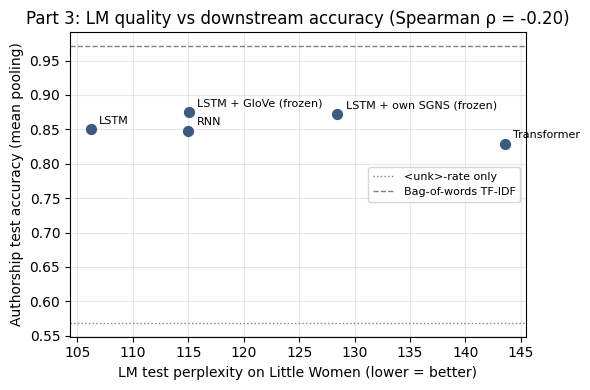

In [10]:
# 8. Does better next-token prediction automatically mean better classification?  (mean pooling)
names = list(LMS)
ppl = np.array([LMS[n][2] for n in names]); acc = np.array([RES[(n, 'mean')]['test_acc'] for n in names])
rho, p = spearmanr(ppl, acc)
print(f'Spearman rank correlation (LM perplexity vs test accuracy): {rho:.2f}  (n={len(names)}, p={p:.2f})')
print('Negative = lower perplexity goes with higher accuracy. With only', len(names), 'models this is descriptive, not significant.')

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(ppl, acc, s=50, color='#3D5A80', zorder=3)
for n, x_, y_ in zip(names, ppl, acc):
    ax.annotate(n, (x_, y_), textcoords='offset points', xytext=(6, 4), fontsize=8)
for base, ls in [('<unk>-rate only', ':'), ('Bag-of-words TF-IDF', '--')]:
    ax.axhline(RES[(base, '-')]['test_acc'], color='grey', ls=ls, lw=1, label=base)
ax.set_xlabel('LM test perplexity on Little Women (lower = better)'); ax.set_ylabel('Authorship test accuracy (mean pooling)')
ax.set_title(f'Part 3: LM quality vs downstream accuracy (Spearman ρ = {rho:.2f})')
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f'{OUT}/fig_part3_ppl_vs_acc.png', dpi=200); plt.show()

## Error analysis
Look at the misclassified test passages for the main comparison. Things to look for: dialogue vs narration, very short passages, passages with lots of `<unk>` (names!), moral/narrator commentary that could be either author, and whether the two models make the **same** mistakes.

In [11]:
# 9. Errors: confusion matrices, overlap, examples
test_df = df[te].reset_index(drop=True)
KEYS = [('LSTM', 'mean'), ('Transformer', 'mean')]
for k in KEYS:
    cm = confusion_matrix(y[te], RES[k]['pred'])
    print(f'{k[0]} ({k[1]}): confusion [[Austen->Austen, Austen->Alcott], [Alcott->Austen, Alcott->Alcott]] = {cm.tolist()}')

wrong = {k: RES[k]['pred'] != y[te] for k in KEYS}
both = wrong[KEYS[0]] & wrong[KEYS[1]]
print(f'\nErrors: LSTM {wrong[KEYS[0]].sum()} | Transformer {wrong[KEYS[1]].sum()} | shared by both {both.sum()}')

test_df['wrong_lstm'], test_df['wrong_tf'] = wrong[KEYS[0]], wrong[KEYS[1]]
test_df['P(Alcott) lstm'] = RES[KEYS[0]]['prob'].round(2); test_df['P(Alcott) tf'] = RES[KEYS[1]]['prob'].round(2)
grp = test_df.assign(any_wrong=test_df.wrong_lstm | test_df.wrong_tf).groupby('any_wrong')[['n_tok', 'unk_rate']].mean().round(3)
print('\nAre errors shorter / lower-<unk> passages?\n', grp)

errs = test_df[test_df.wrong_lstm | test_df.wrong_tf].copy()
errs['true'] = errs.label.map({1: 'Alcott', 0: 'Austen'})
errs = errs.sort_values('P(Alcott) lstm', key=lambda s: (s - 0.5).abs(), ascending=False)   # most confident mistakes first
errs[['true', 'P(Alcott) lstm', 'P(Alcott) tf', 'wrong_lstm', 'wrong_tf', 'n_tok', 'unk_rate', 'text']].to_csv(f'{OUT}/part3_errors.csv', index=False)
pd.set_option('display.max_colwidth', 300)
errs[['true', 'P(Alcott) lstm', 'P(Alcott) tf', 'wrong_lstm', 'wrong_tf', 'unk_rate', 'text']].head(10)

LSTM (mean): confusion [[Austen->Austen, Austen->Alcott], [Alcott->Austen, Alcott->Alcott]] = [[202, 38], [34, 206]]
Transformer (mean): confusion [[Austen->Austen, Austen->Alcott], [Alcott->Austen, Alcott->Alcott]] = [[199, 41], [41, 199]]

Errors: LSTM 72 | Transformer 82 | shared by both 32

Are errors shorter / lower-<unk> passages?
             n_tok  unk_rate
any_wrong                  
False      51.966     0.076
True       49.377     0.075


,true,P(Alcott) lstm,P(Alcott) tf,wrong_lstm,wrong_tf,unk_rate,text
117,Alcott,1.00,0.47,False,True,0.079365,""" we're having a race, and i beat, "" shouted nan. "" i could have run faster, only i was afraid of spilling bess, "" screamed daisy. "" hi! go long! "" cried the princess, giving such a flourish with her whip that the horses ran away, and were seen no more."
25,Alcott,0.99,0.33,False,True,0.076923,""" "" i never had any grandmothers, but if you think it will cure me, i'll let you snip my tongue, "" said nat, heroically, for he dreaded pain, yet did wish to stop fibbing. mr. bhaer smiled, but shook his head."
52,Alcott,0.01,0.37,True,True,0.194444,"after this, tommy proudly advanced to turn a somersault, an accomplishment which he had acquired by painful perseverance, practising in private till every joint of his little frame was black and blue."
225,Alcott,0.99,0.32,False,True,0.000000,it was pleasant to see the boy's face light up when he caught sight of his friend; pleasanter still to see mr.
150,Alcott,0.99,0.49,False,True,0.131148,""" well, put em in my hat and give me a new bit of chalk; i must mark em up, any way. "" billy mounted a peck measure, and looked into the top of the machine, where tommy kept his writing materials. "" there's lots of money in here, "" said billy."
164,Alcott,0.01,0.97,True,False,0.055556,"their quiet talk was interrupted by a shout of delight from teddy, who, to the surprise of every one, did actually catch a trout where no trout had been seen for years."
441,Austen,0.99,0.99,True,True,0.027778,""" elizabeth could bear it no longer. she got up and ran out of the room; and returned no more, till she heard them passing through the hall to the dining parlour."
440,Austen,0.99,0.84,True,True,0.062500,"i was afraid they might not; and we overtook william goulding in his curricle, so i was determined he should know it, and so i let down the side glass next to him, and took off my glove and let my hand just rest upon the window frame, so that he might see the ring, and then i"
296,Austen,0.01,0.66,False,True,0.073171,"collins; "" but if she is really headstrong and foolish, i know not whether she would altogether be a very desirable wife to a man in my situation, who naturally looks for happiness in the marriage state."
250,Austen,0.01,0.86,False,True,0.104167,""" "" mamma, "" cried lydia, "" my aunt says that colonel forster and captain carter do not go so often to miss watson's as they did when they first came; she sees them now very often standing in clarke's library. "" mrs."


In [12]:
# 10. Save a compact summary for the report
summary_out = {f'{k[0]} | {k[1]}': {kk: (float(v) if not isinstance(v, (tuple, np.ndarray)) else [float(x) for x in v])
               for kk, v in RES[k].items() if kk in ('C', 'val_acc', 'test_acc', 'ci', 'macro_f1')} for k in RES}
summary_out['spearman_ppl_vs_acc'] = dict(rho=float(rho), p=float(p), n=len(names))
json.dump(summary_out, open(f'{OUT}/part3_results.json', 'w'), indent=1)
print('Saved part3_results.json, tables, figure and errors CSV to', OUT)

Saved part3_results.json, tables, figure and errors CSV to /content/drive/MyDrive/DSA4213_A1/outputs
